# Wine Data: Min–Max Normalization Analysis

This notebook is about analysis about `wine_data.csv` without a header, selects columns 0–2, and names them `Class label`, `Alcohol`, and `Malic acid`. The file is the classic Wine recognition data, and this analysis intentionally uses only those two numeric measurements to make normalization easy to see.

We will explore the data and class groups, explain the min–max formula, fit the scaler using training data only, compare plots before and after scaling, and verify the result. `Class label` is a category/target. It is never included in the scaler.

**Normalization in this notebook means min–max scaling to [0, 1].** It rescales values; it does not make their distributions normal (bell-shaped).


## 1. Imports and data loading

The source file is expected in the same folder as this notebook. Its rows are comma-separated and have no header row, so we assign descriptive names after selecting the first three columns.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

sns.set_theme(style="whitegrid", context="notebook")
DATA_PATH = Path("wine_data.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Expected wine_data.csv beside this notebook: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH, header=None, usecols=[0, 1, 2])
df.columns = ["Class label", "Alcohol", "Malic acid"]
print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} selected columns")
display(df.head())

Dataset shape: 178 rows × 3 selected columns


,Class label,Alcohol,Malic acid
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36
3,1,14.37,1.95
4,1,13.24,2.59


## 2. Understand the selected columns

- **Class label** identifies one of three wine classes. We treat it as a category, not a continuous measurement.
- **Alcohol** is an amount measurement.
- **Malic acid** is another chemical measurement.

The two measurements have different ranges and units. This matters for methods that use distances or gradient-based optimization: a feature with a numerically larger range can have more influence if features are not scaled.

In [2]:
display(df.dtypes.to_frame("dtype"))
print("Missing values:")
display(df.isna().sum().to_frame("count"))
print("Duplicate rows:", df.duplicated().sum())
print("Class counts:")
display(df["Class label"].value_counts().sort_index().rename("rows").to_frame())
print("Feature summary:")
display(df[["Alcohol", "Malic acid"]].describe().T)

,dtype
Class label,int64
Alcohol,float64
Malic acid,float64


Missing values:


,count
Class label,0
Alcohol,0
Malic acid,0


Duplicate rows: 0
Class counts:


,rows
Class label,
1,59
2,71
3,48


Feature summary:


,count,mean,std,min,25%,50%,75%,max
Alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
Malic acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80


## 3. Inspect raw distributions and class patterns

The first row of plots compares each raw feature's distribution. The scatter plot shows whether these two measurements separate the wine classes. Color is used only to describe the classes; it is not a value passed to the scaler.

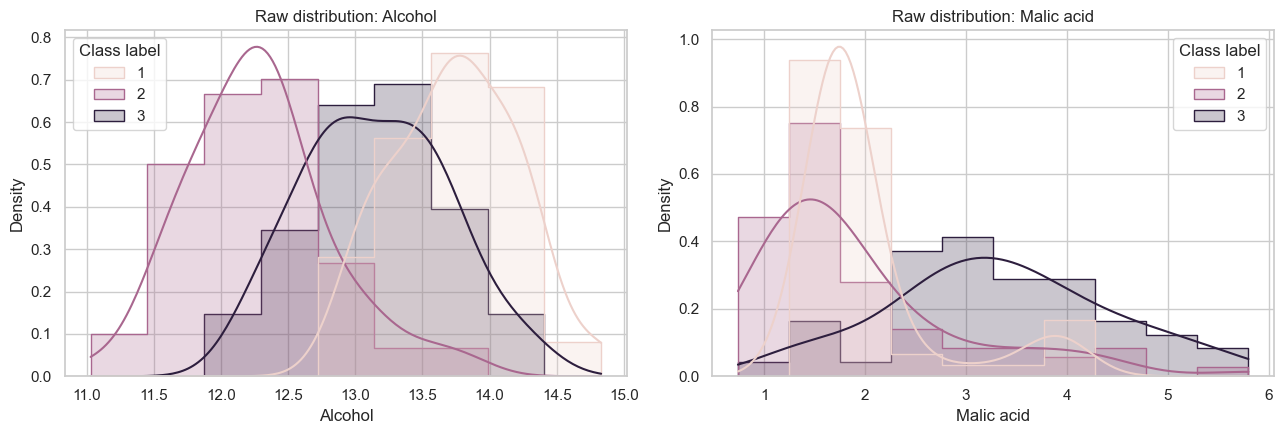

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, feature in zip(axes, ["Alcohol", "Malic acid"]):
    sns.histplot(data=df, x=feature, hue="Class label", kde=True, element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(f"Raw distribution: {feature}")
plt.tight_layout()
plt.show()

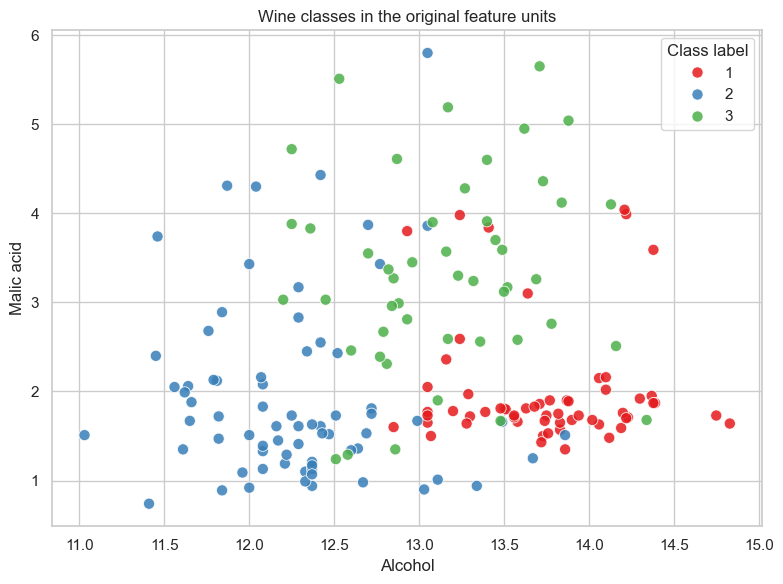

In [4]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="Alcohol", y="Malic acid", hue="Class label", palette="Set1", s=65, alpha=0.85)
plt.title("Wine classes in the original feature units")
plt.xlabel("Alcohol")
plt.ylabel("Malic acid")
plt.legend(title="Class label")
plt.tight_layout()
plt.show()

## 4. Min–max normalization explained

For each feature independently, min–max scaling uses:

$$x_{scaled} = \frac{x - x_{min}}{x_{max} - x_{min}}$$

The minimum maps to 0, the maximum maps to 1, and values between them are placed proportionally. It preserves ordering and relative position within that feature's range, while removing the original unit. The two features are scaled separately; alcohol's minimum and maximum are not used to scale malic acid.

### Important: split first, fit second

We split the data before learning minima and maxima. The scaler is fit only on the training subset, then reused unchanged on the test subset. This avoids letting held-out test data influence preprocessing. Consequently, test values can be slightly less than 0 or greater than 1 if they exceed the training range. That is expected.


## 5. Separate features and class labels

`X` contains only the two continuous measurements. `y` contains class labels for later plotting or model training. Stratification keeps the proportions of each class approximately consistent in train and test subsets.

In [5]:
features = ["Alcohol", "Malic acid"]
X = df[features].copy()
y = df["Class label"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")
print("Train class proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename("proportion").to_frame())
print("Test class proportions:")
display(y_test.value_counts(normalize=True).sort_index().rename("proportion").to_frame())

Training rows: 133 | Test rows: 45
Train class proportions:


,proportion
Class label,
1,0.330827
2,0.398496
3,0.270677


Test class proportions:


,proportion
Class label,
1,0.333333
2,0.400000
3,0.266667


## 6. Fit `MinMaxScaler` on training data

`fit` stores the training minimum and maximum for each column. `transform` applies the stored parameters. The DataFrame wrappers retain feature names and original row indexes, which makes the results easier to compare and plot.

In [6]:
scaler = MinMaxScaler(feature_range=(0, 1))
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=features, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=features, index=X_test.index
)

parameters = pd.DataFrame(
    {"training minimum": scaler.data_min_, "training maximum": scaler.data_max_,
     "range": scaler.data_range_}, index=features
)
display(parameters)
print("First normalized training rows:")
display(X_train_scaled.head())

,training minimum,training maximum,range
Alcohol,11.03,14.83,3.80
Malic acid,0.74,5.80,5.06


First normalized training rows:


,Alcohol,Malic acid
8,1.000000,0.177866
104,0.389474,0.195652
36,0.592105,0.177866
78,0.342105,0.049407
2,0.560526,0.320158


## 7. Verify the transformation

For each non-constant feature, the training minimum should be 0 and maximum 1. Test extrema need not match those values because the test data was not used to fit the scaler. We also check that the class label did not enter the transformed feature table.

In [7]:
print("Training normalized ranges:")
display(pd.DataFrame({"min": X_train_scaled.min(), "max": X_train_scaled.max()}))
print("Test normalized ranges:")
display(pd.DataFrame({"min": X_test_scaled.min(), "max": X_test_scaled.max()}))
assert np.allclose(X_train_scaled.min().to_numpy(), 0)
assert np.allclose(X_train_scaled.max().to_numpy(), 1)
assert list(X_train_scaled.columns) == features
print("Checks passed: training features span [0, 1], and only the two measurements were scaled.")

Training normalized ranges:


,min,max
Alcohol,0.0,1.0
Malic acid,0.0,1.0


Test normalized ranges:


,min,max
Alcohol,0.139474,0.881579
Malic acid,0.029644,0.970356


Checks passed: training features span [0, 1], and only the two measurements were scaled.


## 8. Compare distributions before and after scaling

These plots use the training subset so the displayed values correspond to the data used to fit the scaler. Notice that the shape and ordering are retained, while each horizontal axis now has a [0, 1] range. Normalization does not make skewed data symmetric or remove outliers.

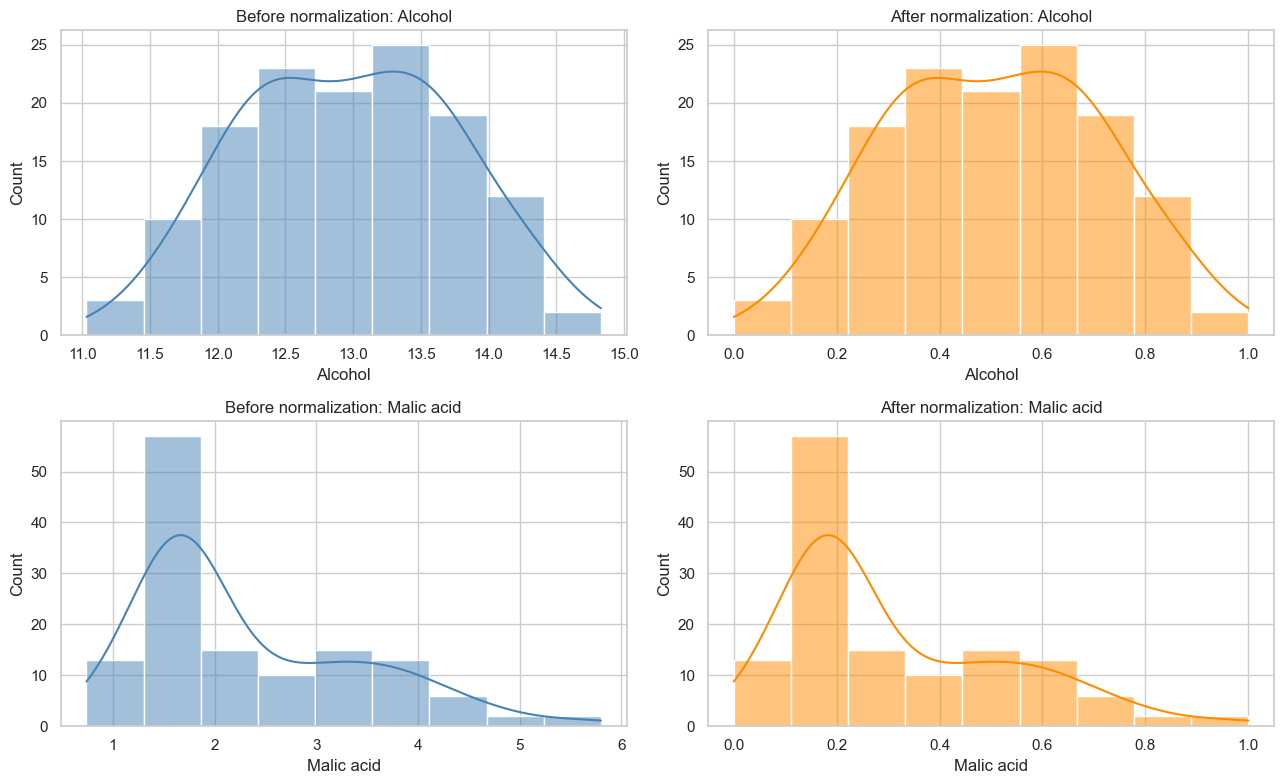

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, feature in enumerate(features):
    sns.histplot(X_train[feature], kde=True, ax=axes[row, 0], color="steelblue")
    axes[row, 0].set_title(f"Before normalization: {feature}")
    sns.histplot(X_train_scaled[feature], kde=True, ax=axes[row, 1], color="darkorange")
    axes[row, 1].set_title(f"After normalization: {feature}")
plt.tight_layout()
plt.show()

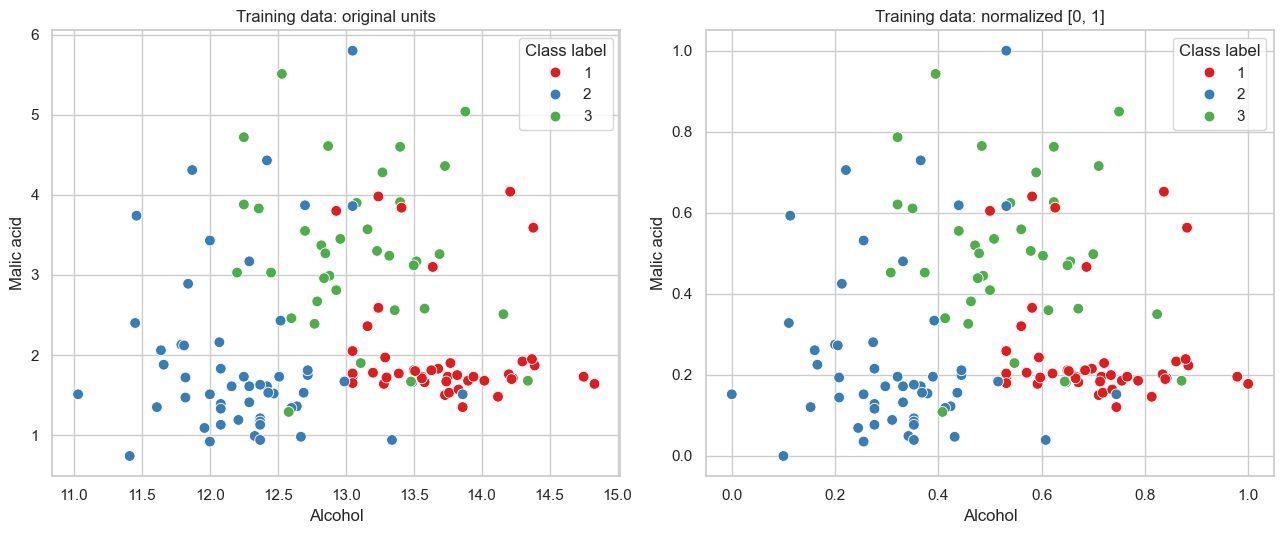

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
train_raw = X_train.join(y_train.rename("Class label"))
train_scaled = X_train_scaled.join(y_train.rename("Class label"))
sns.scatterplot(data=train_raw, x="Alcohol", y="Malic acid", hue="Class label", palette="Set1", s=60, ax=axes[0])
axes[0].set_title("Training data: original units")
sns.scatterplot(data=train_scaled, x="Alcohol", y="Malic acid", hue="Class label", palette="Set1", s=60, ax=axes[1])
axes[1].set_title("Training data: normalized [0, 1]")
plt.tight_layout()
plt.show()

## 9. See the arithmetic for real samples

This table places original and normalized values next to one another. For a sample row, the normalized alcohol value is its distance above the training alcohol minimum divided by the full training alcohol range. The same calculation is independently applied to malic acid.

In [10]:
sample = X_train.head(8).copy()
comparison = pd.concat(
    [sample.add_suffix(" (original)"), X_train_scaled.loc[sample.index].add_suffix(" (normalized)"),
     y_train.loc[sample.index].rename("Class label")], axis=1
)
display(comparison)
row_index = sample.index[0]
manual = (X_train.loc[row_index] - X_train.min()) / (X_train.max() - X_train.min())
print("Manual formula for first displayed training row:")
display(manual.rename("manual normalized value").to_frame())
assert np.allclose(manual.values, X_train_scaled.loc[row_index].values)

,Alcohol (original),Malic acid (original),Alcohol (normalized),Malic acid (normalized),Class label
8,14.83,1.64,1.000000,0.177866,1
104,12.51,1.73,0.389474,0.195652,2
36,13.28,1.64,0.592105,0.177866,1
78,12.33,0.99,0.342105,0.049407,2
2,13.16,2.36,0.560526,0.320158,1
172,14.16,2.51,0.823684,0.349802,3
125,12.07,2.16,0.273684,0.280632,2
12,13.75,1.73,0.715789,0.195652,1


Manual formula for first displayed training row:


,manual normalized value
Alcohol,1.000000
Malic acid,0.177866


## 10. When to use it, and limitations

- Min–max normalization can help distance-sensitive methods such as k-nearest neighbors and can make optimization easier when features have very different scales.
- Scaling does not guarantee a better model. Many tree-based methods are not very sensitive to feature scales.
- Min–max scaling is sensitive to outliers because extreme values set the range. If an extreme value is present, investigate it before choosing a scaling method.
- A normalized value is relative to the training range; it is not a percentage, probability, or measure of wine quality.
- Keep this fitted scaler and reuse it for future observations. For cross-validation or production modeling, put scaling inside a scikit-learn `Pipeline` to ensure each training fold learns its own parameters.
- Class labels are not normalized because they identify categories. They can be used as a target or as plot colors, as done here.

### Summary

The attached example's two measurements have now been examined and min–max normalized through a leakage-safe train/test workflow. `X_train_scaled` and `X_test_scaled` contain the scaled feature values; `y_train` and `y_test` retain the original wine classes. The visual comparisons show that scaling changes units and ranges while retaining each measurement's ordering and overall pattern.
